# TSIA202a - First Practice Session
The goal of this first practical work is to experiment the estimation of second order moments for
random processes, and to simply compare them with their theoretical version.

Let consider the following real processes:
-  White Noise (denoted $\text{WN}$) $Z_t$ with variance $\sigma^2$ (use `np.random.normal`)
-  $X_t=a+bZ_t+Z_{t-1}$ where $Z_t \sim \text{WN}\left(0,\sigma^2\right)$
- $X_t = \sum_{k=0}^{K}2^{-k}Z_{t-k} + a$ (with $K$ "big enough")
- Harmonic Process: $X_t=A_0cos(\lambda_0t+\Phi_0)+Z_t$ where $\lambda \in [0,\pi[,$ $\Phi_0 \sim \mathcal{U}([0,2\pi])$ (*e.g.* `np.random.uniform`)

For each of them:
1. Compute the theoretical mean and autocovariance of the previous mentioned real processes using the formulas $\mathbb{E}(X_n)$ and $\mathrm{Cov}(X_{n},X_{n+h})$.
2. Compute their empirical mean and empirical autocovariance function using course's formulas in python.
3. Plot the theoretical operator and empirical estimators for various sampling many times and comment.
4. For a given number $ T \in \{10, 100, 500, 1000\}$ of samples $X_1, \dots, X_T$:
  - for a given draw, compute the mean squared error (MSE) $\frac{1}{T}\sum_t (\gamma_{t} - \hat{\gamma_{t}})^2$ between the theoretical and the empirical autocovariance function denoted $\gamma$ and $\hat{\gamma}$ respectively.
  - Repeat the previous step $100$ times and saves all the results.
  - compute the boxplot of the MSE for each $T$ and comment.





In [ ]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(100)

White Noise $Z_t$

We have by definition:

$$E[Z] = 0$$
$$
Cov(Z_n+h,Z_n) = \sigma^2  \text{ if } h=0
$$
$$
Cov(Z_n+h,Z_n) = 0  \text{ Otherwise}
$$

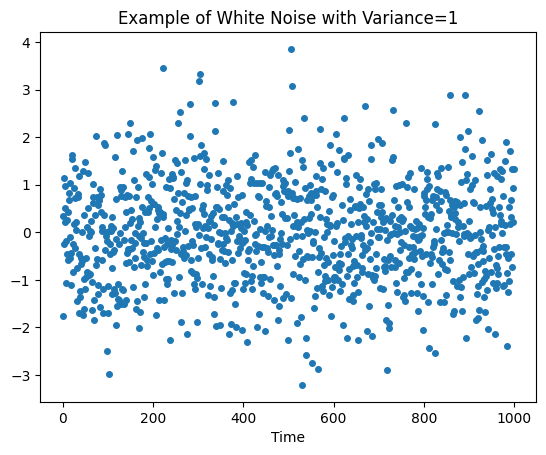

/usr/local/lib/python3.10/dist-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.10/dist-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


nan


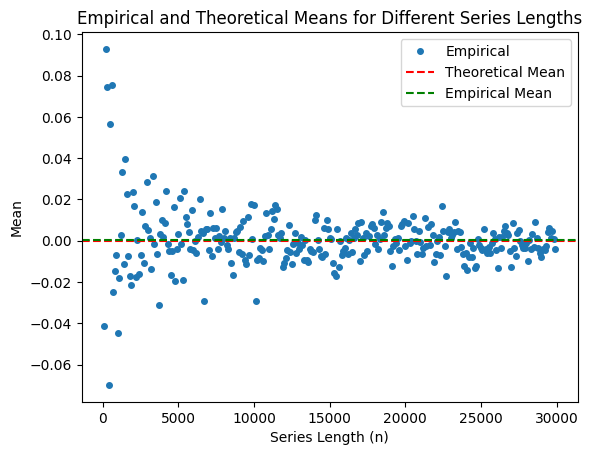

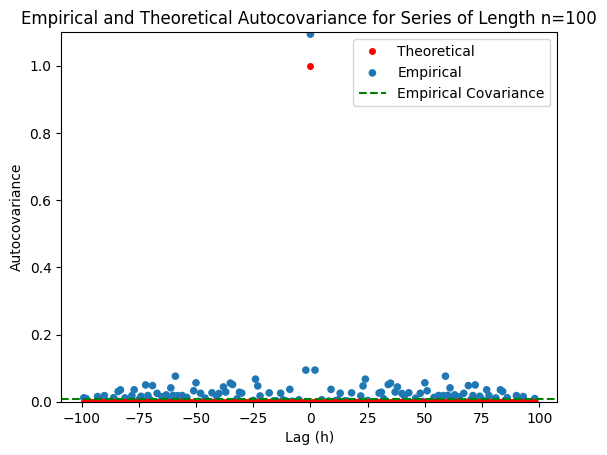

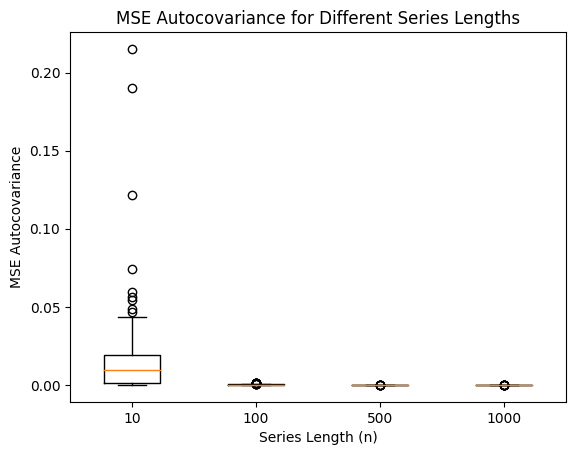

In [ ]:
def calculate_empirical_autocovariance(x, lag):
    n = len(x)
    mean_x = np.mean(x)
    sum_term = lambda t: (x[t + lag] - mean_x) * np.conj(x[t] - mean_x)
    summation = lambda start, finish: sum([sum_term(t) for t in range(start, finish)])

    if np.abs(lag) > n - 1:
        return 0
    elif lag >= 0:
        return (1/n) * summation(0, n - lag)
    else:
        return (1/n) * summation(-lag, n)

def generate_white_noise_series(size):
    return np.random.normal(0, 1, size)

def plot_white_noise_series(time_series, title):
    plt.figure()
    plt.title(title)
    plt.xlabel('Time')
    plt.plot(range(len(time_series)), time_series, 'o', markersize=4, label='White Noise')
    plt.show()

def plot_mean_comparison(n_values, empirical_means, theoretical_mean):
    plt.figure()
    plt.plot(n_values, empirical_means, 'o', label='Empirical', markersize=4)
    plt.axhline(y=theoretical_mean, color='r', linestyle='--', label='Theoretical Mean')
    plt.axhline(y=np.mean(empirical_means[1:]), color='green', linestyle='--', label='Empirical Mean')
    print(np.mean(empirical_means))
    plt.title('Empirical and Theoretical Means for Different Series Lengths')
    plt.xlabel('Series Length (n)')
    plt.ylabel('Mean')
    plt.legend()
    plt.show()

def plot_autocovariance_comparison(hs, empirical_autocovs, theoretical_autocovs, series_length):
    plt.figure()
    plt.plot(hs, theoretical_autocovs, 'o', label='Theoretical', markersize=4, color='red')
    plt.scatter(hs, empirical_autocovs, marker='o', label="Empirical", s=30, edgecolors='none')
    plt.axhline(y=np.mean(empirical_autocovs), color='green', linestyle='--', label='Empirical Covariance')
    plt.ylim(0, 1.1)
    plt.title(f'Empirical and Theoretical Autocovariance for Series of Length n={series_length}')
    plt.xlabel('Lag (h)')
    plt.ylabel('Autocovariance')
    plt.legend()
    plt.show()

def calculate_mse_autocovariance(t_values):
    mses = []
    for t in t_values:
        theoretical_ac = np.zeros(t)
        theoretical_ac[0] = 1
        mse_values = []
        for _ in range(100):
            time_series_t = generate_white_noise_series(t)
            empirical_ac = [calculate_empirical_autocovariance(time_series_t, h) for h in range(t-1)]
            mse_values.append((1/t) * sum([(theoretical_ac[0] - empirical_ac[0])**2]))
        mses.append(mse_values)
    return mses

def plot_mse_comparison(t_values, mses):
    plt.figure()
    bp = plt.boxplot(mses, labels=t_values)
    plt.title('MSE Autocovariance for Different Series Lengths')
    plt.xlabel('Series Length (n)')
    plt.ylabel('MSE Autocovariance')
    plt.show()

# Example usage:
time_series = generate_white_noise_series(1000)
plot_white_noise_series(time_series, f'Example of White Noise with Variance={1}')

step = 100
n_values = np.arange(0, 30000, step)
empirical_means = [np.mean(generate_white_noise_series(n)) for n in n_values]
plot_mean_comparison(n_values, empirical_means, 0)

series_length = 100
hs_autocov = np.arange(-(series_length-1), series_length-1)
empirical_autocovs = [calculate_empirical_autocovariance(time_series, h) for h in hs_autocov]
theoretical_autocovs = [1 if h == 0 else 0 for h in hs_autocov]
plot_autocovariance_comparison(hs_autocov, empirical_autocovs, theoretical_autocovs, series_length)

vector_lengths = [10, 100, 500, 1000]
mses_autocovariance = calculate_mse_autocovariance(vector_lengths)
plot_mse_comparison(vector_lengths, mses_autocovariance)

$X_t=a+bZ_t+Z_{t-1}$ where $Z_t \sim \text{WN}\left(0,\sigma^2\right)$
$$E[X_t] =E[a+bZ_t+Z_{t-1}]= a+bE[Z_t]+E[Z_{t-1}]=a$$
$$
Cov(X_{t+h},X_t) = Cov(a+bZ_{t+h}+Z_{t+h-1},a+bZ_t+Z_{t-1})
$$
$$
= Cov(a,a) + Cov(a,bZ_t) +Cov(a,Z_{t-1}) +Cov(bZ_{t+h},a) +Cov(bZ_{t+h},bZ_t) +Cov(bZ_{t+h},Z_{t-1}) +Cov(Z_{t+h-1},a) +Cov(Z_{t+h-1},bZ_t) +Cov(Z_{t+h-1},Z_{t-1})
$$
$$
= b^2Cov(Z_{t+h},Z_t) + bCov(Z_{t+h},Z_{t-1})+bCov(Z_{t+h-1},Z_t) +Cov(Z_{t+h-1},Z_{t-1})
$$
Thus,
$$
Cov(X_{t+h},X_t) = \sigma^2b^2+\sigma^2  \text{ if } h=0
$$
$$
Cov(X_{t+h},X_t) = b\sigma^2  \text{ if } h=\pm1
$$
$$
Cov(X_{t+h},X_t) = 0  \text{ Otherwise}
$$

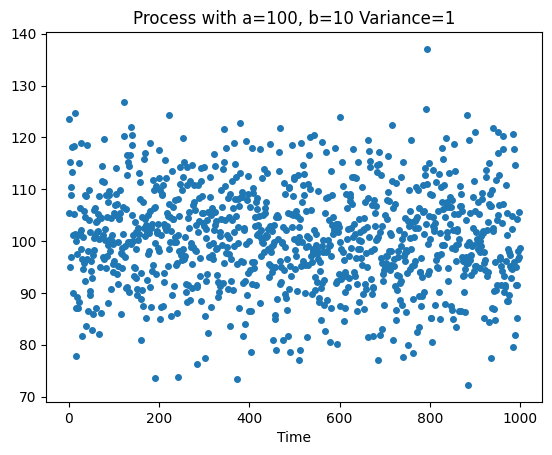

/usr/local/lib/python3.10/dist-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.10/dist-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


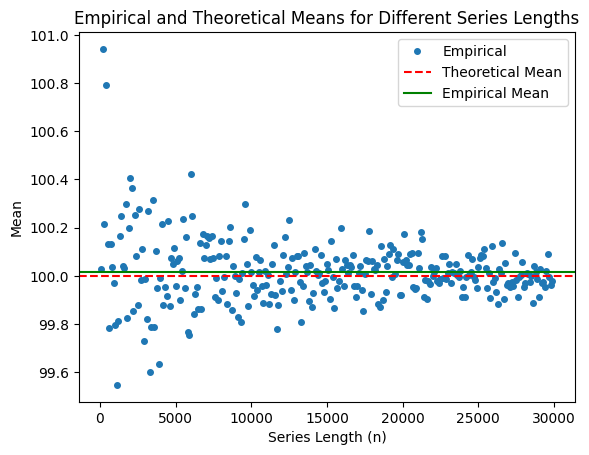

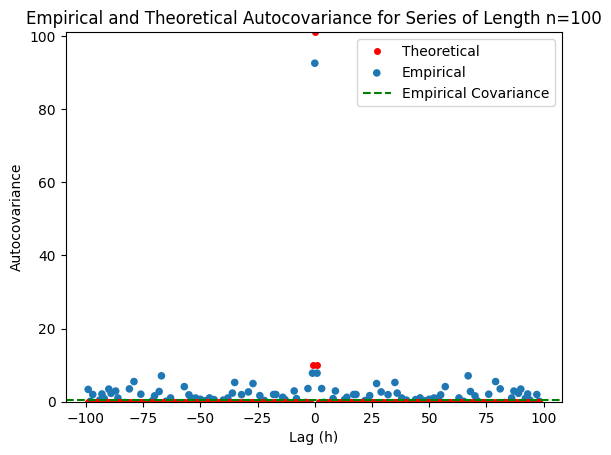

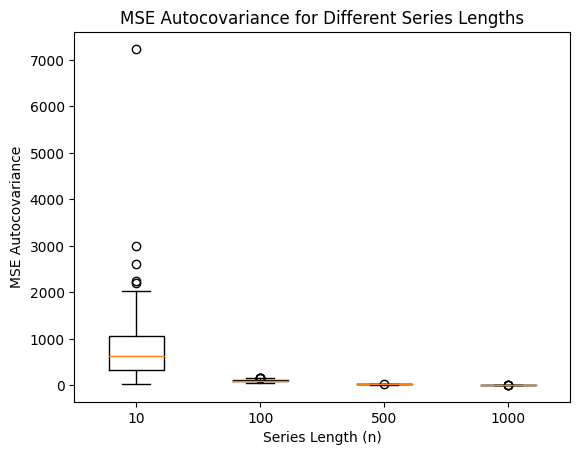

In [ ]:
def calculate_empirical_autocovariance(x, lag):
    n = len(x)
    mean_x = np.mean(x)
    sum_term = lambda t: (x[t + lag] - mean_x) * np.conj(x[t] - mean_x)
    summation = lambda start, finish: sum([sum_term(t) for t in range(start, finish)])

    if np.abs(lag) > n - 1:
        return 0
    elif lag >= 0:
        return (1/n) * summation(0, n - lag)
    else:
        return (1/n) * summation(-lag, n)

def backshift(x, k):
    shifted_array = np.zeros(k)
    truncated_array = x[:-k] if k > 0 else x
    return np.concatenate((shifted_array, truncated_array))

def X_t(size):
    z_t = np.random.normal(0, 1, size)
    return 100+10* z_t+ backshift(z_t, 1)

def plot_X_t(time_series, title):
    plt.figure()
    plt.title(title)
    plt.xlabel('Time')
    plt.plot(range(len(time_series)), time_series, 'o', markersize=4, label='White Noise')
    plt.show()

def plot_mean_comparison(n_values, empirical_means, theoretical_mean):
    plt.figure()
    plt.plot(n_values, empirical_means, 'o', label='Empirical', markersize=4)
    plt.axhline(y=theoretical_mean, color='r', linestyle='--', label='Theoretical Mean')
    plt.axhline(y=np.mean(empirical_means[1:]), color='green', label='Empirical Mean')
    plt.title('Empirical and Theoretical Means for Different Series Lengths')
    plt.xlabel('Series Length (n)')
    plt.ylabel('Mean')
    plt.legend()
    plt.show()

def plot_autocovariance_comparison(hs, empirical_autocovs, theoretical_autocovs, series_length):
    plt.figure()
    plt.plot(hs, theoretical_autocovs, 'o', label='Theoretical', markersize=4, color='red')
    plt.scatter(hs, empirical_autocovs, marker='o', label="Empirical", s=30, edgecolors='none')
    plt.axhline(y=np.mean(empirical_autocovs), color='green', linestyle='--', label='Empirical Covariance')
    plt.ylim(0, 101.1)
    plt.title(f'Empirical and Theoretical Autocovariance for Series of Length n={series_length}')
    plt.xlabel('Lag (h)')
    plt.ylabel('Autocovariance')
    plt.legend()
    plt.show()

def calculate_mse_autocovariance(t_values):
    mses = []
    for t in t_values:
        theoretical_ac = np.zeros(t)
        theoretical_ac[0] = 1
        mse_values = []
        for _ in range(100):
            time_series_t = X_t(t)
            empirical_ac = [calculate_empirical_autocovariance(time_series_t, h) for h in range(t-1)]
            mse_values.append((1/t) * sum([(theoretical_ac[0] - empirical_ac[0])**2]))
        mses.append(mse_values)
    return mses

def plot_mse_comparison(t_values, mses):
    plt.figure()
    bp = plt.boxplot(mses, labels=t_values)
    plt.title('MSE Autocovariance for Different Series Lengths')
    plt.xlabel('Series Length (n)')
    plt.ylabel('MSE Autocovariance')
    plt.show()

# Example usage:
time_series = X_t(1000)
plot_X_t(time_series, f'Process with a={100}, b={10} Variance={1}')

step = 100
n_values = np.arange(0, 30000, step)
empirical_means = [np.mean(X_t(n)) for n in n_values]
plot_mean_comparison(n_values, empirical_means, 100)

series_length = 100
hs_autocov = np.arange(-(series_length-1), series_length-1)
empirical_autocovs = [calculate_empirical_autocovariance(time_series, h) for h in hs_autocov]
theoretical_autocovs = [101 if h == 0 else (10 if h == 1 or h == -1 else 0) for h in hs_autocov]
plot_autocovariance_comparison(hs_autocov, empirical_autocovs, theoretical_autocovs, series_length)

vector_lengths = [10, 100, 500, 1000]
mses_autocovariance = calculate_mse_autocovariance(vector_lengths)
plot_mse_comparison(vector_lengths, mses_autocovariance)

- $X_t = \sum_{k=0}^{K}2^{-k}Z_{t-k} + a$ (with $K$ "big enough")
$$E[X_t] = \sum_{k=0}^{K}2^{-k}E[Z_{t-k}] + a= a$$
$$
 Cov(X_{n+h}, X_{n}) = Cov(\sum_{k=0}^{K}2^{-k}Z_{t-k+h}, \sum_{k=0}^{K}2^{-k}Z_{t-k}) = E[\sum_{k_1=0}^{K}\sum_{k_2=0}^{K} 2^{-k_1-k_2}Z_{n+h-k_1}Z_{n-k_2}]
$$
This is because $Cov(X,a) = 0$
   
   Knowing that $E[Z_{n+h-k_1}Z_{n-k_2}] = \sigma^2$ if $n+h-k_1 = n-k_2$, Otherwise it is zero. Thus, $k_1 = k_2+h$, and knowing $k_2 <=K$ and $k_1 <=K$ we find bounds for $k_2$:
   $$
    {\frac {|h|-h} 2} \le k_2 \le K-{\frac{|h|+h} 2}
  $$
  Thus,
  $$
E[\sum_{k_1=0}^{K}\sum_{k_2=0}^{K} 2^{-k_1-k_2}Z_{n+h-k_1}Z_{n-k_2}] = \sum_{k=\frac {|h|-h} 2}^{K-{\frac{|h|+h} 2}} 2^{-2k-h}E[Z_{n-k_2}^2] = \sigma^22^{-h}\sum_{k=\frac {|h|-h} 2}^{K-{\frac{|h|+h} 2}} 2^{-2k}
  $$
   Since K is very big, we can treat this as a geometric series and we get:
$$
Cov(X_{t+h},X_t) = \sigma^22^{-h}{\frac 1 2^{|h|-h}} {\frac 1  {1- {\frac 1 4}}} = \sigma^22^{-h}\frac 4 3
$$

<ipython-input-124-b841dec65933>:21: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  return [100 + np.sum(z_t[i - k + 10] * 1 / 2 ** k for k in range(11)) for i in range(size)]


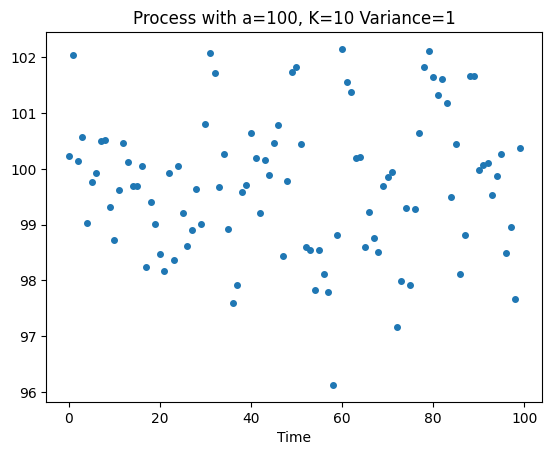

/usr/local/lib/python3.10/dist-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.10/dist-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


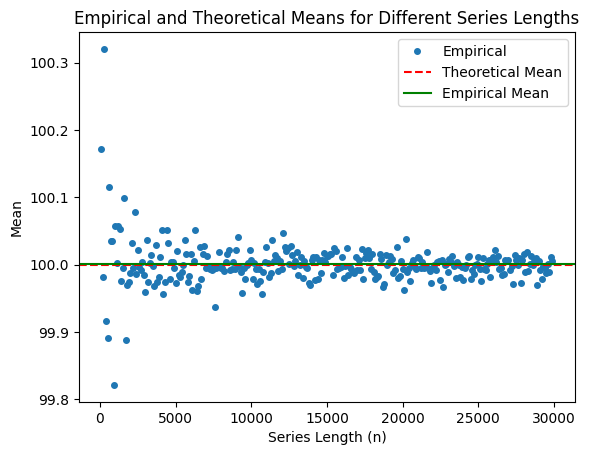

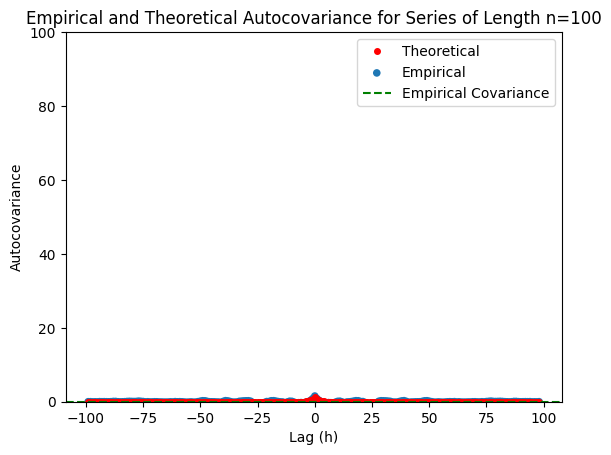

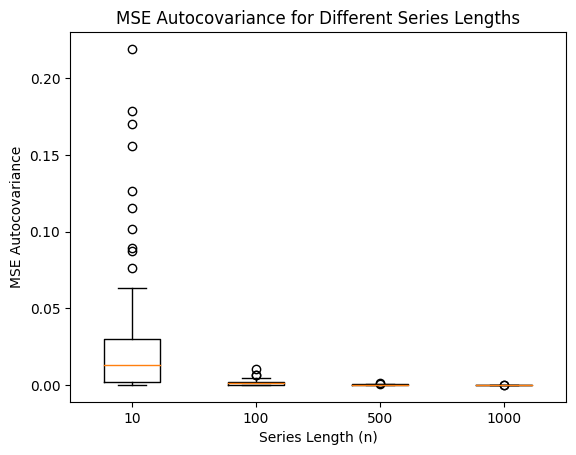

In [ ]:
def calculate_empirical_autocovariance(x, lag):
    n = len(x)
    mean_x = np.mean(x)
    sum_term = lambda t: (x[t + lag] - mean_x) * np.conj(x[t] - mean_x)
    summation = lambda start, finish: sum([sum_term(t) for t in range(start, finish)])

    if np.abs(lag) > n - 1:
        return 0
    elif lag >= 0:
        return (1/n) * summation(0, n - lag)
    else:
        return (1/n) * summation(-lag, n)

def backshift(x, k):
    shifted_array = np.zeros(k)
    truncated_array = x[:-k] if k > 0 else x
    return np.concatenate((shifted_array, truncated_array))

def X_t(size):
    z_t = np.random.normal(0, 1, size + 10)
    return [100 + np.sum(z_t[i - k + 10] * 1 / 2 ** k for k in range(11)) for i in range(size)]

def plot_X_t(time_series, title):
  plt.figure()
  plt.title(title)
  plt.xlabel('Time')
  plt.plot(range(len(time_series)), time_series, 'o', markersize=4, label='White Noise')
  plt.show()

def plot_mean_comparison(n_values, empirical_means, theoretical_mean):
    plt.figure()
    plt.plot(n_values, empirical_means, 'o', label='Empirical', markersize=4)
    plt.axhline(y=theoretical_mean, color='r', linestyle='--', label='Theoretical Mean')
    plt.axhline(y=np.mean(empirical_means[1:]), color='green', label='Empirical Mean')
    plt.title('Empirical and Theoretical Means for Different Series Lengths')
    plt.xlabel('Series Length (n)')
    plt.ylabel('Mean')
    plt.legend()
    plt.show()

def plot_autocovariance_comparison(hs, empirical_autocovs, theoretical_autocovs, series_length):
    plt.figure()
    plt.plot(hs, theoretical_autocovs, 'o', label='Theoretical', markersize=4, color='red')
    plt.scatter(hs, empirical_autocovs, marker='o', label="Empirical", s=30, edgecolors='none')
    plt.axhline(y=np.mean(empirical_autocovs), color='green', linestyle='--', label='Empirical Covariance')
    plt.ylim(0, 100)
    plt.title(f'Empirical and Theoretical Autocovariance for Series of Length n={series_length}')
    plt.xlabel('Lag (h)')
    plt.ylabel('Autocovariance')
    plt.legend()
    plt.show()

def calculate_mse_autocovariance(t_values):
    mses = []
    for t in t_values:
        theoretical_ac = np.zeros(t)
        theoretical_ac[0] = 1
        mse_values = []
        for _ in range(100):
            time_series_t = X_t(t)
            empirical_ac = [calculate_empirical_autocovariance(time_series_t, h) for h in range(t-1)]
            mse_values.append((1/t) * sum([(theoretical_ac[0] - empirical_ac[0])**2]))
        mses.append(mse_values)
    return mses

def plot_mse_comparison(t_values, mses):
    plt.figure()
    bp = plt.boxplot(mses, labels=t_values)
    plt.title('MSE Autocovariance for Different Series Lengths')
    plt.xlabel('Series Length (n)')
    plt.ylabel('MSE Autocovariance')
    plt.show()

time_series = X_t(100)
plot_X_t(time_series, f'Process with a={100}, K={10} Variance={1}')

step = 100
n_values = np.arange(0, 30000, step)
empirical_means = [np.mean(X_t(n)) for n in n_values]
plot_mean_comparison(n_values, empirical_means, 100)

series_length = 100
hs_autocov = np.arange(-(series_length-1), series_length-1, dtype=float)
empirical_autocovs = [calculate_empirical_autocovariance(time_series, int(h)) for h in hs_autocov]
theoretical_autocovs = [4/3 * pow(2,-np.abs(h)) for h in hs_autocov]
plot_autocovariance_comparison(hs_autocov, empirical_autocovs, theoretical_autocovs, series_length)

vector_lengths = [10, 100, 500, 1000]
mses_autocovariance = calculate_mse_autocovariance(vector_lengths)
plot_mse_comparison(vector_lengths, mses_autocovariance)

$X_t=A_0cos(\lambda_0t+\Phi_0)+Z_t$ where $\lambda \in [0,\pi[,$ $\Phi_0 \sim \mathcal{U}([0,2\pi])$

Since $\Phi_0$ follow a uniform distribution, we can have:
$$
F_{f}(t) = P(t < A_0cos(\lambda_0t+\Phi_0)) = P(\frac{t}{A_0} < cos(\lambda_0t+\Phi_0))
$$
However, due to the restricted range of the arccosine function, further calculations become impractical. The expectation is computed in the standard way:
$$
E[X_t] = E[A_0cos(\lambda_0t+\Phi_0)] + E[Z_t] = E[A_0cos(\lambda_0t+\Phi_0)]=  \frac{A_0}{2\pi}\int_0^{2\pi} cos(\lambda_0t+u)du = \frac{A_0}{2\pi}(sin(2\pi+\lambda_0t)-sin(\lambda_0t)) = 0
$$
$$
E[X_t] = 0
$$
$$
Cov(X_{n+h},X_n) = E[X_{n+h}X_n]= A_0^2E[cos(\lambda_0n+\lambda_0h+\Phi_0)cos(\lambda_0n+\Phi_0)] + A_0E[cos(\lambda_0n+\lambda_0h)+\Phi_0)Z_n] + A_0E[Z_{n+h}cos(\lambda_0n+\Phi_0)] + E[Z_{n+h}Z_n]= \frac{A_0^2} 2 E[cos(2\lambda_0n + 2u + \lambda_0h)cos(-\lambda_0h)] + \sigma^2\delta(h) = \frac{A_0^2} 2 \int_0^{2\pi}cos(2\lambda_0n + 2u + \lambda_0h) du + \frac{A_0^2} 2cos(-\lambda_0h) + \sigma^2\delta(h)= \frac{A_0^2} 2cos(-\lambda_0h)+ \sigma^2\delta(h)
$$
$$
Cov(X_n+h,X_n) = \frac{A_0^2}{2}cos(-\lambda_0h) + \sigma^2\delta(h)
$$

[-2.616826272675129, 1.5080168256119462, 2.9816873149838927, 3.137171561559037, 0.39035383328177736, -2.0843372872750914, 0.7919760316408357, -0.9627058016612786, 2.256068818195138, 0.7599010011011107, -0.08029137266687247, -0.45893195367466555, -3.309241896643613, 0.2104452821403492, -0.08757112581127213, 1.566710221826975, 1.9070997888750028, -1.5949671893720918, -3.2013728764460514, -1.6864566844506155, 1.0578773969104498, 2.945525552801112, 0.8471412160337661, -2.441480656506027, 0.4736705724016972, -2.618651717968817, -0.26364615510484085, 1.0817404920178988, 0.5824970619577547, -0.5223822430184806, -1.3069844924253673, -0.7503974922976853, 0.7361373123566658, 0.7139009767128832, 2.0134884042922923, 0.9813540375049469, -0.6401651914568276, -1.6509378333786442, -1.7481134287282816, 0.4972628342882153, 3.886901577902325, 3.0705378204993146, -2.1839317419737716, -1.2112839921307725, -1.709152085937964, -0.7720322256402591, 2.7558435641416947, 2.5429385281693087, 0.1945653782207426, -

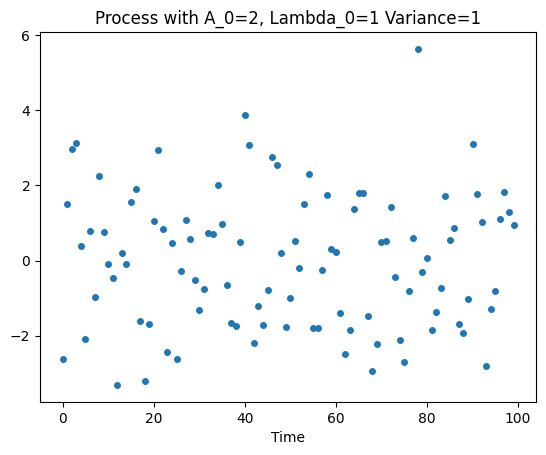

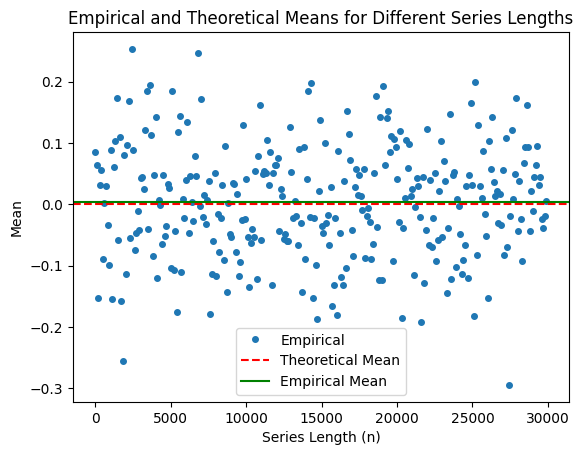

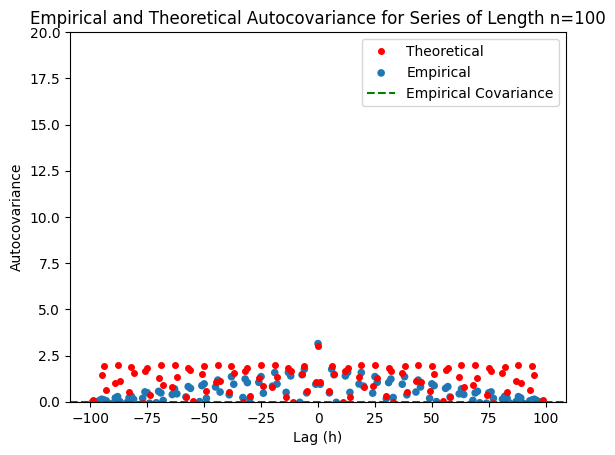

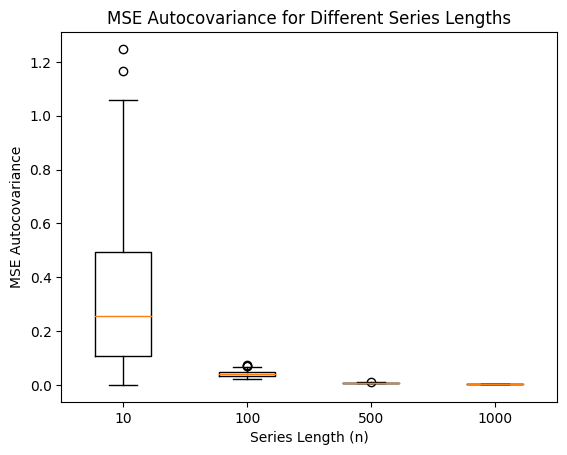

In [ ]:
def calculate_empirical_autocovariance(x, lag):
    n = len(x)
    mean_x = np.mean(x)
    sum_term = lambda t: (x[t + lag] - mean_x) * np.conj(x[t] - mean_x)
    summation = lambda start, finish: sum([sum_term(t) for t in range(start, finish)])

    if np.abs(lag) > n - 1:
        return 0
    elif lag >= 0:
        return (1/n) * summation(0, n - lag)
    else:
        return (1/n) * summation(-lag, n)

def X_t(size):
    z_t = np.random.normal(0,1,size)
    phi_0 = np.random.uniform(0, 2*np.pi, size)
    return [[z_t[x] + 2*np.cos(x+phi_0[0])] for x in range(size)]

def plot_X_t(time_series, title):
    plt.figure()
    plt.title(title)
    plt.xlabel('Time')
    plt.plot(range(len(time_series)), time_series, 'o', markersize=4, label='White Noise')
    plt.show()

def plot_mean_comparison(n_values, empirical_means, theoretical_mean):
    plt.figure()
    plt.plot(n_values, empirical_means, 'o', label='Empirical', markersize=4)
    plt.axhline(y=theoretical_mean, color='r', linestyle='--', label='Theoretical Mean')
    plt.axhline(y=np.mean(empirical_means[1:]), color='green', label='Empirical Mean')
    plt.title('Empirical and Theoretical Means for Different Series Lengths')
    plt.xlabel('Series Length (n)')
    plt.ylabel('Mean')
    plt.legend()
    plt.show()

def plot_autocovariance_comparison(hs, empirical_autocovs, theoretical_autocovs, series_length):
    plt.figure()
    plt.plot(hs, theoretical_autocovs, 'o', label='Theoretical', markersize=4, color='red')
    plt.scatter(hs, empirical_autocovs, marker='o', label="Empirical", s=30, edgecolors='none')
    plt.axhline(y=np.mean(empirical_autocovs), color='green', linestyle='--', label='Empirical Covariance')
    plt.ylim(0, 20)
    plt.title(f'Empirical and Theoretical Autocovariance for Series of Length n={series_length}')
    plt.xlabel('Lag (h)')
    plt.ylabel('Autocovariance')
    plt.legend()
    plt.show()

def calculate_mse_autocovariance(t_values):
    mses = []
    for t in t_values:
        theoretical_ac = np.zeros(t)
        theoretical_ac[0] = 1
        mse_values = []
        for _ in range(100):
            time_series_t = X_t(t)
            empirical_ac = [calculate_empirical_autocovariance(time_series_t, h) for h in range(t-1)]
            mse_values.append((1/t) * sum([(theoretical_ac[0] - empirical_ac[0])**2]))
        mses.append(mse_values)
    return mses

def plot_mse_comparison(t_values, mses):
    plt.figure()
    bp = plt.boxplot(mses, labels=t_values)
    plt.title('MSE Autocovariance for Different Series Lengths')
    plt.xlabel('Series Length (n)')
    plt.ylabel('MSE Autocovariance')
    plt.show()

time_series = X_t(100)
print(time_series)
plot_X_t(time_series, f'Process with A_0={2}, Lambda_0={1} Variance={1}')

step = 100
n_values = np.arange(0, 30000, step)
empirical_means = [np.mean(X_t(100)) for n in n_values]
plot_mean_comparison(n_values, empirical_means, 0)

series_length = 100
hs_autocov = np.arange(-(series_length-1), series_length)
empirical_autocovs = [calculate_empirical_autocovariance(time_series, h) for h in hs_autocov]
theoretical_autocovs = [2*np.cos(-h)+1 if h==0 else 2*np.cos(-h) for h in hs_autocov]
plot_autocovariance_comparison(hs_autocov, empirical_autocovs, theoretical_autocovs, series_length)

vector_lengths = [10, 100, 500, 1000]
mses_autocovariance = calculate_mse_autocovariance(vector_lengths)
plot_mse_comparison(vector_lengths, mses_autocovariance)